# 01. Load Open QSM Dataset

**Dataset**  
QSM Consensus Paper Example Data  
DOI: `10.5281/zenodo.7795492`

이 노트북은 공개 QSM 데이터셋의 **Siemens / Monopolar / GRE** 데이터를 읽어
기존 MP-PCA 실험에서 사용하던 complex multi-echo GRE 형식으로 복원한다.

실제 파일 구조:
- Magnitude: echo 1~5 각각 `.nii.gz` + `.json`
- Phase: echo 1~5 각각 `.nii.gz` + `.json`
- 총 5 echoes
- 각 echo의 3D NIfTI를 마지막 축으로 stack하여 `(X, Y, Z, 5)` 4D 배열 생성
- 이후 Magnitude + Phase로 complex GRE 복원

사용 폴더:
`converted/SIEMENS/Monopolar/GRE`


### 환경설정

In [3]:
import os
import json
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import ndimage


In [4]:
# ------------------------------------------------------------
# QSM Consensus Paper Example Data 폴더
# ------------------------------------------------------------
DATASET_ROOT = r"C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\QSM_Consensus_Paper_Example_Data_Result_Code"

GRE_DIR = os.path.join(
    DATASET_ROOT,
    "converted",
    "SIEMENS",
    "Monopolar",
    "GRE"
)

N_ECHOES = 5

# 실제 파일명 규칙
mag_paths = [
    os.path.join(
        GRE_DIR,
        f"sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-{echo}_GRE.nii.gz"
    )
    for echo in range(1, N_ECHOES + 1)
]

phase_paths = [
    os.path.join(
        GRE_DIR,
        f"sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-{echo}_GRE.nii.gz"
    )
    for echo in range(1, N_ECHOES + 1)
]

mag_json_paths = [
    os.path.join(
        GRE_DIR,
        f"sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-{echo}_GRE.json"
    )
    for echo in range(1, N_ECHOES + 1)
]

phase_json_paths = [
    os.path.join(
        GRE_DIR,
        f"sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-{echo}_GRE.json"
    )
    for echo in range(1, N_ECHOES + 1)
]

slice_idx = None   # None이면 중앙 slice 자동 선택
echo_idx = 0       # 0 = Echo 1

print("GRE directory:")
print(GRE_DIR)

print("\nMagnitude files:")
for p in mag_paths:
    print(" ", os.path.basename(p))

print("\nPhase files:")
for p in phase_paths:
    print(" ", os.path.basename(p))


GRE directory:
C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\QSM_Consensus_Paper_Example_Data_Result_Code\converted\SIEMENS\Monopolar\GRE

Magnitude files:
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-1_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-2_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-3_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-4_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-5_GRE.nii.gz

Phase files:
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-1_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-2_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-3_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-4_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-5_GRE.nii.gz


### 1. Echo별 Magnitude / Phase NIfTI 불러오기

각 echo의 3D NIfTI를 개별적으로 읽은 뒤 마지막 축으로 쌓아
`(X, Y, Z, 5)` 형태의 4D multi-echo 배열을 만든다.


In [6]:
# 파일 존재 여부 확인
all_paths = mag_paths + phase_paths + mag_json_paths + phase_json_paths
missing = [p for p in all_paths if not os.path.exists(p)]

if missing:
    print("찾지 못한 파일:")
    for p in missing:
        print(" ", p)
    raise FileNotFoundError(
        "\n위 파일을 찾을 수 없습니다. DATASET_ROOT / GRE_DIR 경로를 확인하세요."
    )

mag_list = []
phase_list = []

mag_affine = None
mag_header = None

for echo in range(N_ECHOES):
    mag_img = nib.load(mag_paths[echo])
    phase_img = nib.load(phase_paths[echo])

    mag = mag_img.get_fdata(dtype=np.float32)
    phase = phase_img.get_fdata(dtype=np.float32)

    if mag.shape != phase.shape:
        raise ValueError(
            f"Echo {echo + 1}: Magnitude와 Phase shape이 다릅니다. "
            f"{mag.shape} vs {phase.shape}"
        )

    if echo == 0:
        reference_shape = mag.shape
        mag_affine = mag_img.affine.copy()
        mag_header = mag_img.header.copy()
    else:
        if mag.shape != reference_shape:
            raise ValueError(
                f"Echo {echo + 1}: spatial shape이 Echo 1과 다릅니다. "
                f"{mag.shape} vs {reference_shape}"
            )

        if not np.allclose(mag_img.affine, mag_affine):
            raise ValueError(
                f"Echo {echo + 1}: Magnitude affine이 Echo 1과 다릅니다."
            )

        if not np.allclose(phase_img.affine, mag_affine):
            raise ValueError(
                f"Echo {echo + 1}: Phase affine이 Magnitude Echo 1과 다릅니다."
            )

    mag_list.append(mag)
    phase_list.append(phase)

# 3D × 5 → 4D
magnitude_4d = np.stack(mag_list, axis=-1).astype(np.float32)
phase_raw = np.stack(phase_list, axis=-1).astype(np.float32)

print("Magnitude 4D shape:", magnitude_4d.shape)
print("Phase 4D shape    :", phase_raw.shape)
print("Magnitude dtype   :", magnitude_4d.dtype)
print("Phase dtype       :", phase_raw.dtype)
print("Number of echoes  :", magnitude_4d.shape[-1])

if slice_idx is None:
    slice_idx = magnitude_4d.shape[2] // 2

print("Display slice     :", slice_idx)


Magnitude 4D shape: (176, 256, 144, 5)
Phase 4D shape    : (176, 256, 144, 5)
Magnitude dtype   : float32
Phase dtype       : float32
Number of echoes  : 5
Display slice     : 72


### 2. JSON metadata 확인 + Phase 값 확인

각 echo의 JSON sidecar에서 `EchoTime`, `MagneticFieldStrength` 등을 확인한다.
그 다음 phase 값의 실제 범위를 출력해 phase scaling을 점검한다.


In [8]:
# JSON metadata 읽기
mag_metadata = []
phase_metadata = []

for echo in range(N_ECHOES):
    with open(mag_json_paths[echo], "r", encoding="utf-8") as f:
        mag_meta = json.load(f)

    with open(phase_json_paths[echo], "r", encoding="utf-8") as f:
        phase_meta = json.load(f)

    mag_metadata.append(mag_meta)
    phase_metadata.append(phase_meta)

print("===== Acquisition metadata =====")
for echo, meta in enumerate(mag_metadata, start=1):
    print(
        f"Echo {echo}: "
        f"EchoTime={meta.get('EchoTime', 'N/A')}, "
        f"MagneticFieldStrength={meta.get('MagneticFieldStrength', 'N/A')}, "
        f"Manufacturer={meta.get('Manufacturer', 'N/A')}"
    )

echo_times = [
    meta.get("EchoTime", np.nan)
    for meta in mag_metadata
]

field_strength = mag_metadata[0].get("MagneticFieldStrength", None)

print("\nEcho times [s]:", echo_times)
print("Field strength [T]:", field_strength)

print("\n===== Raw phase range =====")
for echo in range(N_ECHOES):
    ph = phase_raw[..., echo]
    print(
        f"Echo {echo + 1}: "
        f"min={np.nanmin(ph):.4f}, "
        f"max={np.nanmax(ph):.4f}"
    )

global_phase_min = float(np.nanmin(phase_raw))
global_phase_max = float(np.nanmax(phase_raw))

print("\nGlobal raw phase range:")
print(" min =", global_phase_min)
print(" max =", global_phase_max)

# ------------------------------------------------------------
# QSM Consensus example dataset의 Siemens phase scaling
# ------------------------------------------------------------
# 이 데이터셋의 phase가 DICOM 정수 범위 [-4096, 4095]로 저장된 경우:
#     phase_rad = phase_raw * pi / 4096
#
# 이미 [-pi, pi] 근처의 radian 값이라면 그대로 사용한다.
#
# 아래는 값 범위에 따라 자동 판별한다.
# ------------------------------------------------------------

if global_phase_min >= -np.pi - 0.1 and global_phase_max <= np.pi + 0.1:
    print("\nPhase가 이미 radian 범위로 보입니다. 그대로 사용합니다.")
    phase_rad = phase_raw.astype(np.float32)

elif global_phase_min >= -4096.5 and global_phase_max <= 4095.5:
    print("\nPhase가 Siemens/DICOM integer scaling으로 보입니다.")
    print("[-4096, 4095] -> [-pi, pi) 변환을 적용합니다.")
    phase_rad = (phase_raw * (np.pi / 4096.0)).astype(np.float32)

else:
    raise ValueError(
        "예상하지 못한 phase 범위입니다. "
        "JSON/README의 phase scaling 정보를 다시 확인하세요."
    )

print("\nConverted phase range [rad]:")
print(" min =", np.nanmin(phase_rad))
print(" max =", np.nanmax(phase_rad))


===== Acquisition metadata =====
Echo 1: EchoTime=0.00525, MagneticFieldStrength=3, Manufacturer=Siemens
Echo 2: EchoTime=0.01108, MagneticFieldStrength=3, Manufacturer=Siemens
Echo 3: EchoTime=0.01691, MagneticFieldStrength=3, Manufacturer=Siemens
Echo 4: EchoTime=0.02274, MagneticFieldStrength=3, Manufacturer=Siemens
Echo 5: EchoTime=0.02857, MagneticFieldStrength=3, Manufacturer=Siemens

Echo times [s]: [0.00525, 0.01108, 0.01691, 0.02274, 0.02857]
Field strength [T]: 3

===== Raw phase range =====
Echo 1: min=-4096.0000, max=4094.0000
Echo 2: min=-4096.0000, max=4094.0000
Echo 3: min=-4096.0000, max=4094.0000
Echo 4: min=-4096.0000, max=4094.0000
Echo 5: min=-4096.0000, max=4094.0000

Global raw phase range:
 min = -4096.0
 max = 4094.0

Phase가 Siemens/DICOM integer scaling으로 보입니다.
[-4096, 4095] -> [-pi, pi) 변환을 적용합니다.

Converted phase range [rad]:
 min = -3.1415927
 max = 3.1400588


### 3. Magnitude + Phase → Complex GRE 복원

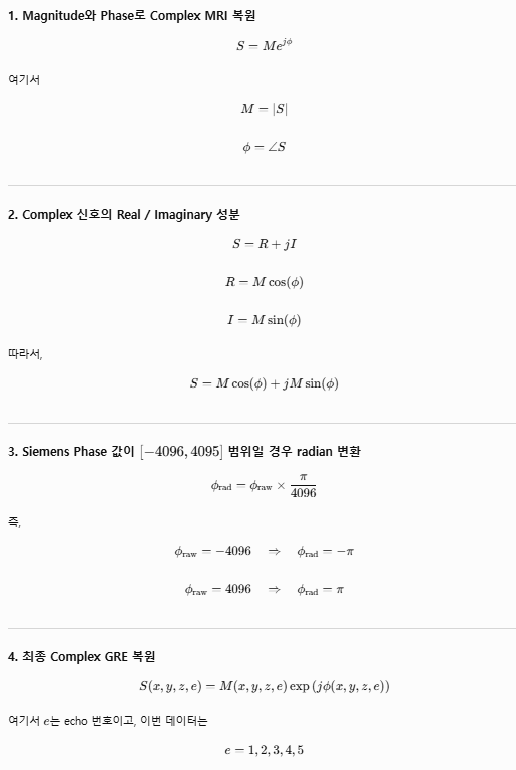

기존 MP-PCA 코드와 연결하기 쉽도록 복원된 complex 데이터를 `meas_gre`라는 변수명으로 둔다.


In [10]:
meas_gre = (
    magnitude_4d.astype(np.float32)
    * np.exp(1j * phase_rad.astype(np.float32))
).astype(np.complex64)

real_4d = meas_gre.real
imag_4d = meas_gre.imag

print("meas_gre shape:", meas_gre.shape)
print("meas_gre dtype:", meas_gre.dtype)
print("n_echoes:", meas_gre.shape[-1])

# 검증: abs(complex)가 원래 magnitude와 거의 같아야 함
mag_reconstructed = np.abs(meas_gre)
max_mag_error = np.max(np.abs(mag_reconstructed - magnitude_4d))
print("Magnitude reconstruction max error:", max_mag_error)


meas_gre shape: (176, 256, 144, 5)
meas_gre dtype: complex64
n_echoes: 5
Magnitude reconstruction max error: 0.00024414062


### 4. Magnitude / Phase / Real / Imag 시각화

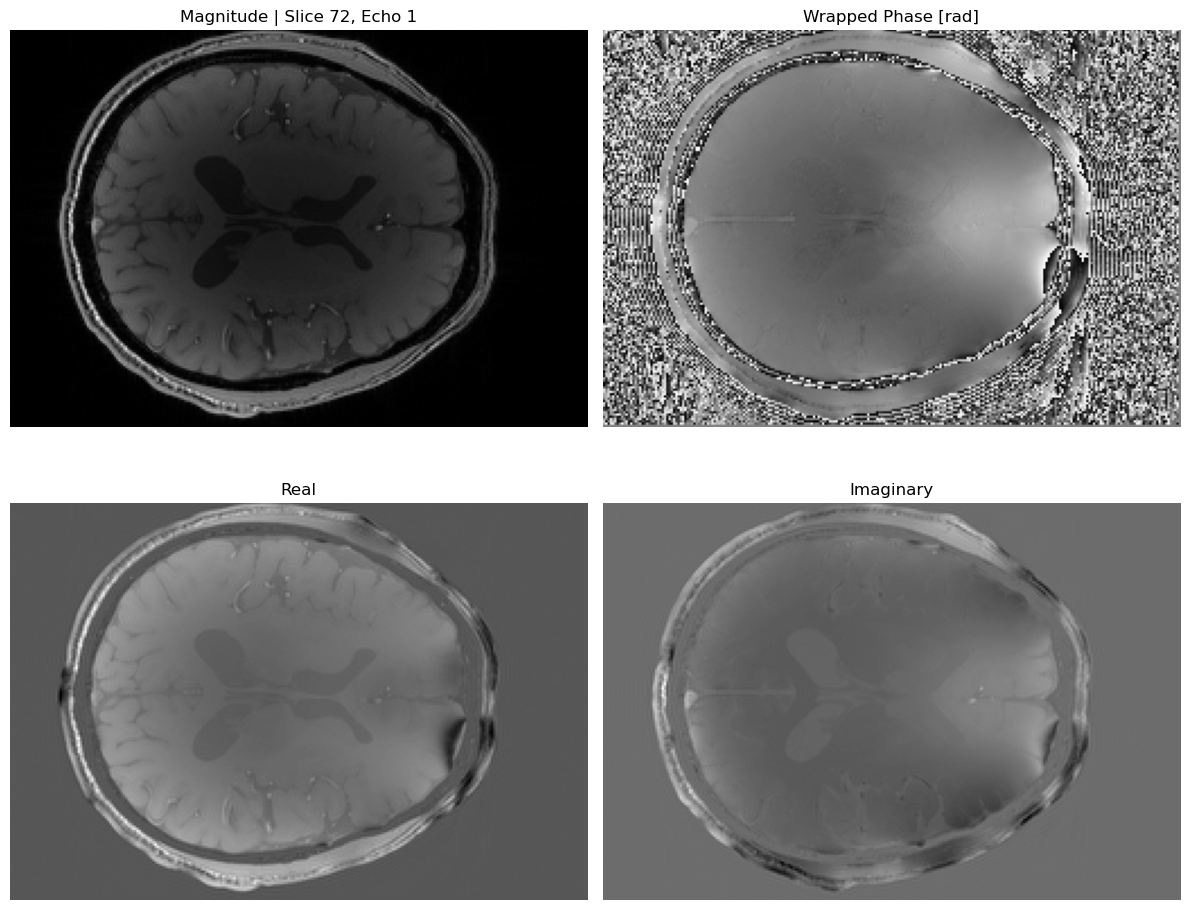

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

ax[0, 0].imshow(magnitude_4d[:, :, slice_idx, echo_idx], cmap="gray")
ax[0, 0].set_title(f"Magnitude | Slice {slice_idx}, Echo {echo_idx + 1}")

ax[0, 1].imshow(phase_rad[:, :, slice_idx, echo_idx], cmap="gray")
ax[0, 1].set_title("Wrapped Phase [rad]")

ax[1, 0].imshow(real_4d[:, :, slice_idx, echo_idx], cmap="gray")
ax[1, 0].set_title("Real")

ax[1, 1].imshow(imag_4d[:, :, slice_idx, echo_idx], cmap="gray")
ax[1, 1].set_title("Imaginary")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.show()


### 5. Brain mask 준비

현재 `converted/SIEMENS/Monopolar/GRE` 폴더에는 magnitude/phase 입력 데이터가 있고,
이 노트북에서는 우선 파이프라인 확인을 위해 Echo 1 magnitude에서 간단한 preview mask를 생성한다.

**최종 논문 실험에서는 동일한 brain mask를 모든 noise level과 모든 denoising 방법에 고정 적용해야 한다.**
가능하면 QSM 처리 과정에서 생성한 brain mask 또는 별도의 표준 brain extraction 결과를 사용하는 것이 좋다.


In [14]:
def make_preview_brain_mask(mag3d, threshold_fraction=0.08):
    # 논문 최종용이 아니라 데이터 확인/코드 테스트용 단순 mask
    x = np.asarray(mag3d, dtype=np.float32)

    positive = x[x > 0]
    if positive.size == 0:
        raise ValueError("Magnitude 영상에 양수 신호가 없습니다.")

    scale = np.percentile(positive, 99)
    binary = x > (threshold_fraction * scale)

    binary = ndimage.binary_closing(binary, iterations=2)
    binary = ndimage.binary_fill_holes(binary)

    labels, n_labels = ndimage.label(binary)
    if n_labels == 0:
        raise ValueError("Brain mask를 생성하지 못했습니다.")

    sizes = ndimage.sum(binary, labels, range(1, n_labels + 1))
    largest_label = int(np.argmax(sizes)) + 1
    return (labels == largest_label)

mask = make_preview_brain_mask(magnitude_4d[..., 0])

print("mask shape:", mask.shape)
print("mask dtype:", mask.dtype)
print("mask voxels:", np.sum(mask))


mask shape: (176, 256, 144)
mask dtype: bool
mask voxels: 2899729


### 6. Brain mask 확인

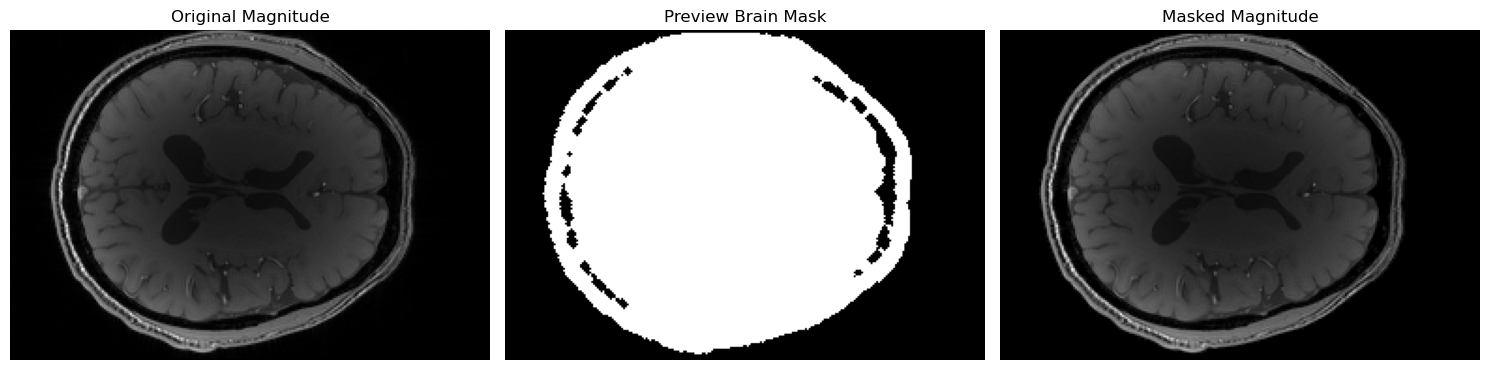

In [16]:
magnitude_slice = magnitude_4d[:, :, slice_idx, echo_idx]
mask_slice = mask[:, :, slice_idx]
masked_magnitude = magnitude_slice * mask_slice

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(magnitude_slice, cmap="gray")
ax[0].set_title("Original Magnitude")
ax[0].axis("off")

ax[1].imshow(mask_slice, cmap="gray")
ax[1].set_title("Preview Brain Mask")
ax[1].axis("off")

ax[2].imshow(masked_magnitude, cmap="gray")
ax[2].set_title("Masked Magnitude")
ax[2].axis("off")

plt.tight_layout()
plt.show()


### 7. Echo별 기본 신호 확인

In [18]:
print("===== Dataset summary =====")
print("Spatial shape :", meas_gre.shape[:3])
print("Echoes        :", meas_gre.shape[-1])
print("Complex dtype :", meas_gre.dtype)
print("Mask voxels   :", np.sum(mask))

print("\n===== Mean magnitude inside brain mask =====")
for e in range(meas_gre.shape[-1]):
    mean_signal = np.mean(np.abs(meas_gre[..., e])[mask])
    print(f"Echo {e + 1}: {mean_signal:.4f}")


===== Dataset summary =====
Spatial shape : (176, 256, 144)
Echoes        : 5
Complex dtype : complex64
Mask voxels   : 2899729

===== Mean magnitude inside brain mask =====
Echo 1: 376.5416
Echo 2: 294.1318
Echo 3: 249.3957
Echo 4: 212.9763
Echo 5: 177.9716


### 8. 기존 MP-PCA 코드와 연결할 변수

이 셀까지 실행하면 기존 실험에서 사용하던 핵심 변수와 같은 역할을 한다.

- `meas_gre` : `(X, Y, Z, 5)` complex GRE
- `mask` : `(X, Y, Z)` boolean brain mask
- `real_4d` : Real component
- `imag_4d` : Imaginary component
- `magnitude_4d` : `(X, Y, Z, 5)` Magnitude
- `phase_raw` : 원본 phase 값
- `phase_rad` : radian으로 변환된 wrapped phase
- `echo_times` : JSON에서 읽은 echo time 목록
- `field_strength` : JSON에서 읽은 magnetic field strength
- `mag_affine`, `mag_header` : NIfTI 저장 시 재사용할 공간정보

새 공개 데이터는 **5 echoes**이므로:

- Split MP-PCA: 5 features
- Real+Imag Combined MP-PCA: 10 real-valued features
- Direct Complex MP-PCA: 5 complex-valued features
- Magnitude MP-PCA: 5 magnitude features

이후 noise 추가와 denoising 코드에서도 `N_ECHOES=5`를 기준으로 처리한다.


### 9. 선택 사항: 변환 결과 저장

`SAVE_PROCESSED = True`로 바꾸면 complex GRE와 preview mask를 `.npz`로 저장한다.

파일 크기가 클 수 있으므로 기본값은 `False`이다.


In [21]:
SAVE_PROCESSED = True

if SAVE_PROCESSED:
    output_dir = "./data/processed"
    os.makedirs(output_dir, exist_ok=True)

    output_path = os.path.join(
        output_dir,
        "qsm_consensus_siemens_monopolar_complex.npz"
    )

    np.savez_compressed(
        output_path,
        meas_gre=meas_gre,
        mask_brain=mask.astype(bool),
        echo_times=np.asarray(echo_times, dtype=np.float64),
        field_strength=(
            np.nan if field_strength is None else float(field_strength)
        ),
    )

    print("Saved:", output_path)
else:
    print("SAVE_PROCESSED=False : 저장하지 않았습니다.")


Saved: ./data/processed\qsm_consensus_siemens_monopolar_complex.npz
